# Territory Vision — Classificação de imagens de satélite com CNN

**Global Solution 2026.2 · Aprendizado Profundo com Redes Neurais Convolucionais · FIAP**

**Integrantes:** João Victor Alves de Abreu (RM 564946) e Rodrigo Kenshin Viana Matayoshi (RM 564026).

Este notebook reúne todo o trabalho: preparação dos dados, três arquiteturas de CNN treinadas do zero, comparação pela validação, avaliação final no teste e a aplicação web em Gradio.

| Seção | Conteúdo |
|---|---|
| 1 | Problema e objetivo |
| 2 | Dados e preparação |
| 3 | Arquiteturas e treinamento |
| 4 | Comparação e avaliação |
| 5 | Análise crítica |
| 6 | Aplicação web |
| 7 | Uso de IA generativa |
| 8 | Conclusões, limitações e melhorias |

**Como executar (Google Colab ou Jupyter):** rode as células em ordem. A célula de instalação é necessária só em ambiente novo; o treinamento baixa o EuroSAT (≈ 91 MB) e leva alguns minutos em CPU. A última célula de código inicia a aplicação web.

In [ ]:
%pip install "tensorflow-cpu>=2.16,<2.21" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "gradio>=4,<6" pillow

## 1. Problema e objetivo

Interpretar imagens de satélite manualmente é lento e exige especialistas. O objetivo é treinar uma **CNN própria** (sem pesos pré-treinados) que classifique imagens do EuroSAT em quatro tipos de uso e cobertura do solo — **Forest**, **Industrial**, **Residential** e **River** —, investigar como mudanças na arquitetura afetam o desempenho e disponibilizar o melhor modelo em uma aplicação web.

## 2. Dados e preparação

- **Base:** EuroSAT RGB oficial (Zenodo 7711810), imagens Sentinel‑2 de 64 × 64 pixels.
- **Amostra:** 200 imagens por classe (800 no total), sorteadas com semente fixa — o recomendado pelo enunciado.
- **Divisão estratificada 60/20/20:** 480 treino, 160 validação e 160 teste, com 40 imagens por classe em validação e teste. O teste só é usado depois da escolha do modelo.
- **Pré-processamento:** conversão para RGB, redimensionamento para 64 × 64 e **normalização dos pixels para [0, 1]** (divisão por 255), o que deixa as entradas na mesma escala e estabiliza o gradiente.
- **Rastreabilidade:** `outputs/split.json` guarda o caminho de cada imagem em cada conjunto; o código confirma que não há imagem repetida entre conjuntos.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = globals().get("OUT", Path("outputs") if Path("outputs").exists() else Path("../outputs"))
CLASSES = ["Forest", "Industrial", "Residential", "River"]
split = json.loads((OUT / "split.json").read_text())

contagem = pd.DataFrame({nome: Counter(Path(p).parent.name for p in caminhos) for nome, caminhos in split.items()}
                        ).loc[CLASSES].rename(columns={"train": "treino", "val": "validação", "test": "teste"})
contagem.loc["Total"] = contagem.sum()
conjuntos = [set(v) for v in split.values()]
print("Imagens repetidas entre conjuntos:", len(conjuntos[0] & conjuntos[1]) + len(conjuntos[0] & conjuntos[2]) + len(conjuntos[1] & conjuntos[2]))
contagem

Imagens repetidas entre conjuntos: 0


,treino,validação,teste
Forest,120,40,40
Industrial,120,40,40
Residential,120,40,40
River,120,40,40
Total,480,160,160


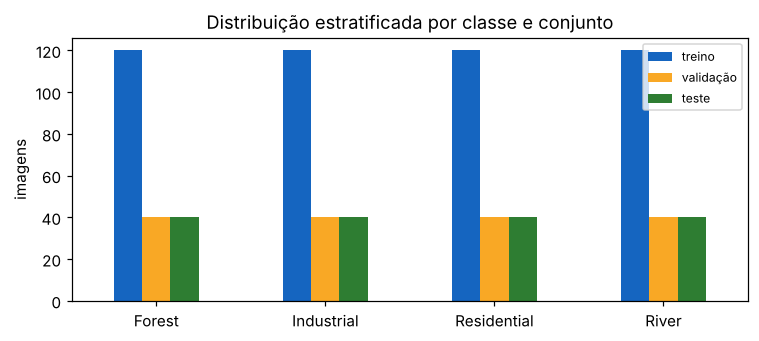

In [2]:
ax = contagem.drop(index="Total").plot.bar(figsize=(7, 3.2), color=["#1565c0", "#f9a825", "#2e7d32"], rot=0)
ax.set(title="Distribuição estratificada por classe e conjunto", ylabel="imagens")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Arquiteturas e treinamento

Todas as redes seguem o mesmo padrão: blocos **Conv2D (3 × 3, ReLU, padding *same*) + MaxPooling2D (2 × 2)**, depois **Flatten → Dense (ReLU) → [Dropout] → Dense(4, softmax)**.

- **Conv2D** aprende filtros que detectam padrões locais (bordas, texturas de telhados, linhas de rio, copas de árvores). Filtros das camadas seguintes combinam esses padrões em estruturas maiores.
- **ReLU** introduz não linearidade e evita o desaparecimento do gradiente.
- **MaxPooling** reduz a resolução pela metade, diminui o custo e dá tolerância a pequenos deslocamentos.
- **Dense** combina as características extraídas para decidir a classe; **Dropout** desliga neurônios aleatoriamente no treino para reduzir o sobreajuste.
- **Softmax** transforma as saídas em quatro pontuações que somam 1.

**Treinamento:** perda *sparse categorical cross-entropy* (rótulos inteiros), otimizador **Adam**, lotes de 32, até 12 épocas e **EarlyStopping** (paciência 3, restaura os melhores pesos pela perda de validação). A cada lote, a retropropagação calcula o gradiente da perda em relação a cada peso e o Adam atualiza os pesos com taxa de aprendizado adaptativa.

| Experimento | Blocos conv (filtros) | Dense | Dropout | Taxa de aprendizado | Hipótese testada |
|---|---|---|---|---|---|
| CNN 1 (base) | 16 → 32 | 64 | — | 0,001 | Rede pequena e rápida como referência |
| CNN 2 | 32 → 64 | 128 | 0,25 | 0,001 | Mais filtros captam texturas finas (industrial × residencial); dropout controla o sobreajuste |
| CNN 3 | 32 → 64 → 128 | 128 | 0,35 | 0,0005 | Rede mais profunda, mais regularizada e com passo menor generaliza melhor? |

A célula a seguir confere, camada a camada, o número de parâmetros de cada arquitetura (pesos + vieses) e compara com o valor registrado pelo Keras durante o treino.

In [3]:
resultados = json.loads((OUT / "results.json").read_text())

def contar_parametros(filtros, densa, entrada=(64, 64, 3), classes=4):
    h, w, c = entrada
    linhas = []
    for f in filtros:
        p = 3 * 3 * c * f + f
        linhas.append((f"Conv2D {f} filtros 3×3", f"{h}×{w}×{f}", p))
        h, w, c = h // 2, w // 2, f
        linhas.append(("MaxPooling2D 2×2", f"{h}×{w}×{c}", 0))
    achatado = h * w * c
    linhas.append(("Flatten", str(achatado), 0))
    linhas.append((f"Dense {densa} (ReLU)", str(densa), achatado * densa + densa))
    linhas.append((f"Dense {classes} (softmax)", str(classes), densa * classes + classes))
    return pd.DataFrame(linhas, columns=["camada", "saída", "parâmetros"])

for e in resultados["experiments"]:
    cfg = e["config"]
    tabela = contar_parametros(cfg["filters"], cfg["dense"])
    total = int(tabela["parâmetros"].sum())
    print(f"{cfg['name']}: {total:,} parâmetros calculados · Keras: {e['parameters']:,} · confere: {total == e['parameters']}".replace(",", "."))
contar_parametros([32, 64], 128)

cnn_1: 529.700 parâmetros calculados · Keras: 529.700 · confere: True
cnn_2: 2.117.188 parâmetros calculados · Keras: 2.117.188 · confere: True
cnn_3: 1.142.468 parâmetros calculados · Keras: 1.142.468 · confere: True


,camada,saída,parâmetros
0,Conv2D 32 filtros 3×3,64×64×32,896
1,MaxPooling2D 2×2,32×32×32,0
2,Conv2D 64 filtros 3×3,32×32×64,18496
3,MaxPooling2D 2×2,16×16×64,0
4,Flatten,16384,0
5,Dense 128 (ReLU),128,2097280
6,Dense 4 (softmax),4,516


A maior parte dos parâmetros está na primeira camada densa: na CNN 2, o Flatten entrega 16 × 16 × 64 = 16.384 valores para 128 neurônios (≈ 2,1 milhões de pesos). A CNN 3 tem **menos** parâmetros que a CNN 2, apesar de ser mais profunda, porque o terceiro pooling reduz o mapa para 8 × 8 antes do Flatten.

### Treinamento dos três experimentos (saídas da execução registrada)

In [4]:
"""Experimentos EuroSAT: seleção exclusivamente por validação e teste final único."""
import json, os, random, zipfile, urllib.request
from pathlib import Path
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
SEED=42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError): pass
CLASSES=['Forest','Industrial','Residential','River']
ROOT=Path(os.environ.get('CNN_ROOT',Path.cwd())).resolve()
DATA=ROOT/'data'; OUT=ROOT/'outputs'; DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
archive=DATA/'EuroSAT.zip'
if not archive.exists():
    urllib.request.urlretrieve('https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1', archive)
folder=DATA/'2750'
if not folder.exists() and not (DATA/'EuroSAT_RGB').exists():
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            p=Path(info.filename)
            if p.is_absolute() or '..' in p.parts: raise ValueError('Caminho inseguro no arquivo zip')
        z.extractall(DATA)
if not folder.exists(): folder=DATA/'EuroSAT_RGB'
paths=[]; labels=[]
for label,name in enumerate(CLASSES):
    files=sorted((folder/name).glob('*.jpg'))
    if len(files)<200: raise RuntimeError(f'{name}: esperadas ao menos 200 imagens, encontradas {len(files)}')
    chosen=np.random.default_rng(SEED+label).choice(files,200,replace=False)
    paths.extend(map(str,chosen)); labels.extend([label]*200)
paths=np.array(paths); labels=np.array(labels)
trainval, test=train_test_split(np.arange(len(labels)),test_size=.2,stratify=labels,random_state=SEED)
train, val=train_test_split(trainval,test_size=.25,stratify=labels[trainval],random_state=SEED)
assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
# Converter uma vez mantém as mesmas imagens e normalização para os três experimentos.
def load(ids):
    imgs=[tf.keras.utils.img_to_array(tf.keras.utils.load_img(paths[i],target_size=(64,64)))/255.0 for i in ids]
    return np.asarray(imgs,dtype='float32'),labels[ids]
xtr,ytr=load(train); xv,yv=load(val); xt,yt=load(test)
(OUT/'split.json').write_text(json.dumps({k:[str(Path(paths[i]).relative_to(DATA)) for i in ids] for k,ids in [('train',train),('val',val),('test',test)]},indent=2))
configs=[
    {'name':'cnn_1','filters':[16,32],'dense':64,'dropout':0.0,'lr':0.001},
    {'name':'cnn_2','filters':[32,64],'dense':128,'dropout':0.25,'lr':0.001},
    {'name':'cnn_3','filters':[32,64,128],'dense':128,'dropout':0.35,'lr':0.0005},
]
def make_model(c):
    layers=[tf.keras.layers.Input((64,64,3))]
    for filters in c['filters']:
        layers.extend([tf.keras.layers.Conv2D(filters,3,padding='same',activation='relu'),tf.keras.layers.MaxPooling2D(2)])
    layers += [tf.keras.layers.Flatten(),tf.keras.layers.Dense(c['dense'],activation='relu')]
    if c['dropout']: layers.append(tf.keras.layers.Dropout(c['dropout']))
    layers.append(tf.keras.layers.Dense(4,activation='softmax'))
    model=tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(c['lr']),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model
results=[]
for c in configs:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    model=make_model(c)
    callback=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)
    history=model.fit(xtr,ytr,validation_data=(xv,yv),epochs=12,batch_size=32,callbacks=[callback],verbose=2)
    val_prob=model.predict(xv,verbose=0); val_pred=val_prob.argmax(axis=1)
    model.save(OUT/(c['name']+'.keras'))
    item={'config':c,'epochs_run':len(history.history['loss']),'val_accuracy':float(accuracy_score(yv,val_pred)),
          'val_report':classification_report(yv,val_pred,target_names=CLASSES,output_dict=True,zero_division=0),
          'val_confusion_matrix':confusion_matrix(yv,val_pred,labels=range(4)).tolist(),
          'history':{k:[float(x) for x in v] for k,v in history.history.items()},'parameters':model.count_params()}
    results.append(item)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for ax,key in zip(axes,['loss','accuracy']):
        ax.plot(history.history[key],label='treino'); ax.plot(history.history['val_'+key],label='validação'); ax.set_title(key); ax.legend(); ax.set_xlabel('época')
    fig.tight_layout(); fig.savefig(OUT/(c['name']+'_curvas.png'),dpi=150); plt.close(fig)
# Acurácia de validação decide; empate por menor loss de validação.
best=max(results,key=lambda x:(x['val_accuracy'],-min(x['history']['val_loss'])))
model=tf.keras.models.load_model(OUT/(best['config']['name']+'.keras'))
prob=model.predict(xt,verbose=0); pred=prob.argmax(axis=1)
summary={'classes':CLASSES,'seed':SEED,'counts':{'train':len(train),'validation':len(val),'test':len(test)},
         'selection':'maior acurácia de validação; desempate por menor perda de validação',
         'experiments':results,'best':best['config']['name'],
         'test_report':classification_report(yt,pred,target_names=CLASSES,output_dict=True,zero_division=0),
         'test_confusion_matrix':confusion_matrix(yt,pred,labels=range(4)).tolist()}
(OUT/'results.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
model.save(OUT/'best.keras')
fig,ax=plt.subplots(figsize=(6,5)); cm=np.array(summary['test_confusion_matrix']); im=ax.imshow(cm,cmap='Blues'); fig.colorbar(im,ax=ax)
ax.set(xticks=range(4),yticks=range(4),xticklabels=CLASSES,yticklabels=CLASSES,xlabel='Previsto',ylabel='Real',title='Teste: matriz de confusão')
plt.setp(ax.get_xticklabels(),rotation=30,ha='right')
for i in range(4):
    for j in range(4): ax.text(j,i,str(cm[i,j]),ha='center',va='center')
fig.tight_layout(); fig.savefig(OUT/'matriz_teste.png',dpi=150); plt.close(fig)
print('Modelo selecionado:',summary['best']); print(classification_report(yt,pred,target_names=CLASSES,zero_division=0))


Epoch 1/12


15/15 - 10s - 635ms/step - accuracy: 0.3479 - loss: 1.2185 - val_accuracy: 0.7375 - val_loss: 1.0204


Epoch 2/12


15/15 - 4s - 233ms/step - accuracy: 0.6667 - loss: 0.9272 - val_accuracy: 0.6938 - val_loss: 0.7491


Epoch 3/12


15/15 - 3s - 219ms/step - accuracy: 0.7104 - loss: 0.6841 - val_accuracy: 0.6313 - val_loss: 0.7129


... (59 outputs left out)

15/15 - 4s - 275ms/step - accuracy: 0.8250 - loss: 0.4617 - val_accuracy: 0.8125 - val_loss: 0.4653


Epoch 10/12


15/15 - 5s - 346ms/step - accuracy: 0.8146 - loss: 0.4513 - val_accuracy: 0.8188 - val_loss: 0.4542


Modelo selecionado: cnn_2
              precision    recall  f1-score   support

      Forest       0.95      0.93      0.94        40
  Industrial       0.84      0.80      0.82        40
 Residential       0.78      0.72      0.75        40
       River       0.83      0.95      0.88        40

    accuracy                           0.85       160
   macro avg       0.85      0.85      0.85       160
weighted avg       0.85      0.85      0.85       160



## 4. Comparação e avaliação

A arquitetura final é escolhida **apenas pela validação** (maior acurácia; desempate pela menor perda). O conjunto de teste é avaliado uma única vez, com o modelo já escolhido.

cnn_1 acurácia validação: 0.85 parâmetros: 529700


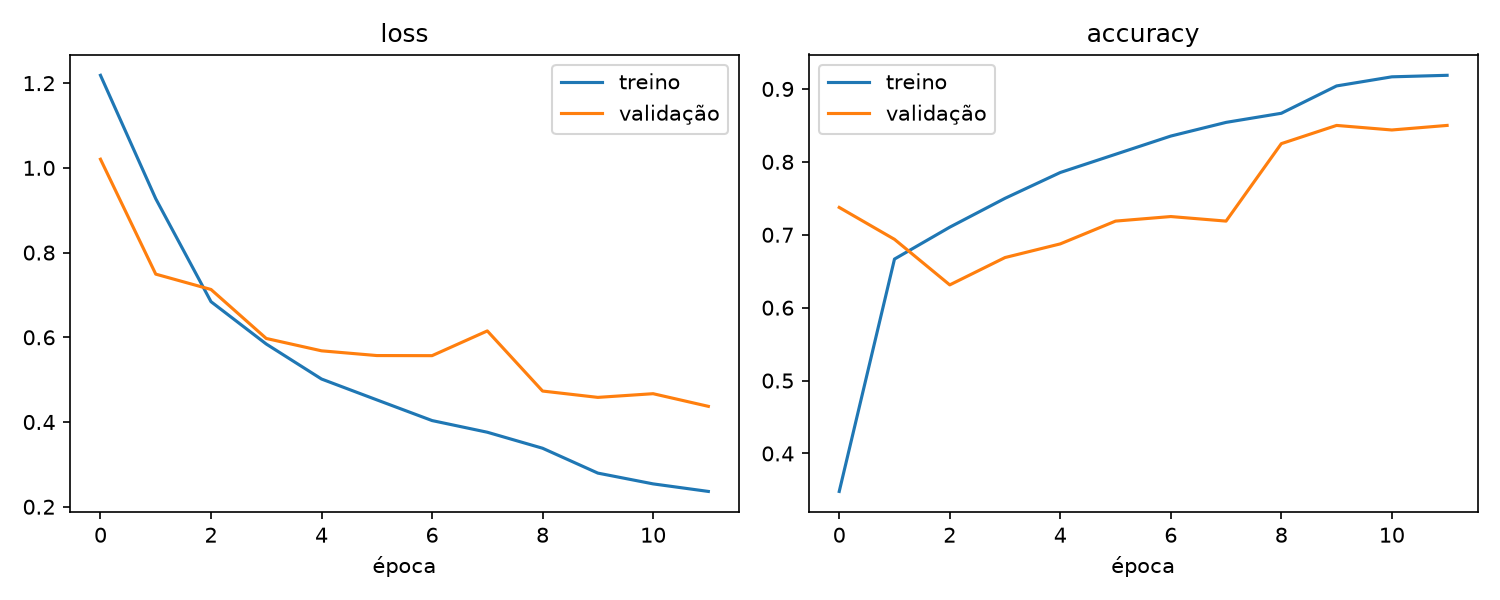

cnn_2 acurácia validação: 0.8688 parâmetros: 2117188


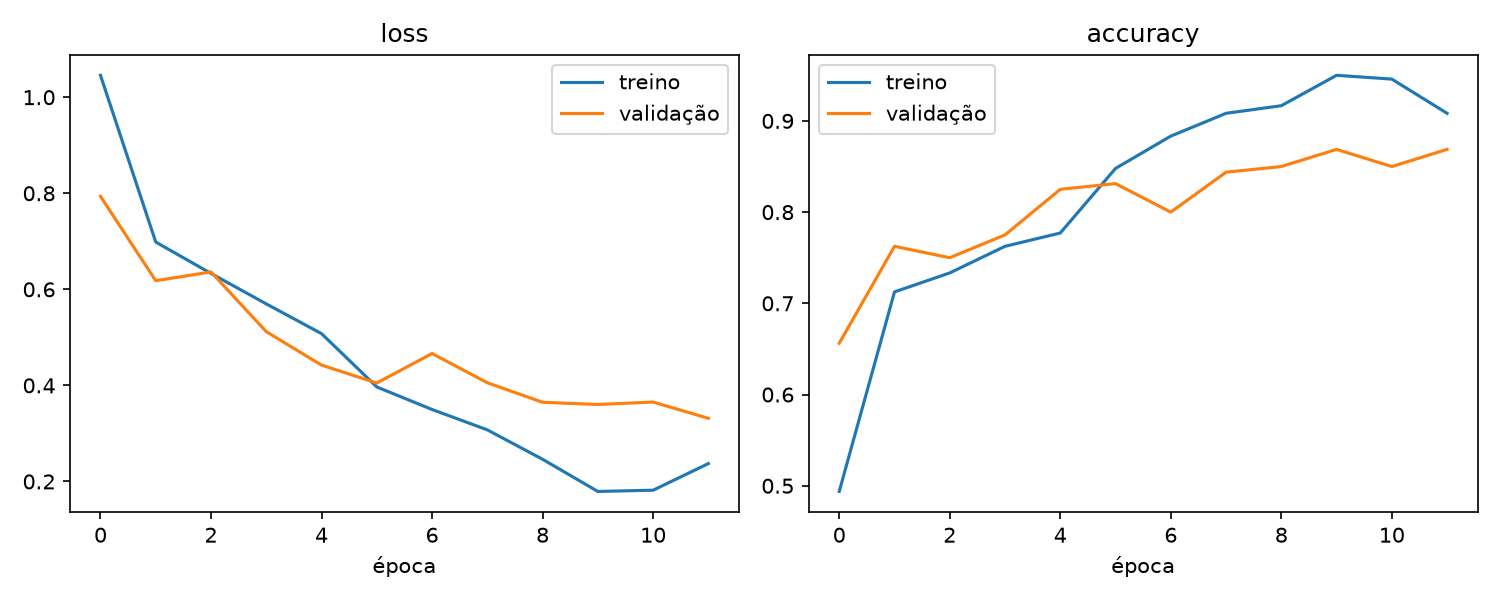

cnn_3 acurácia validação: 0.8313 parâmetros: 1142468


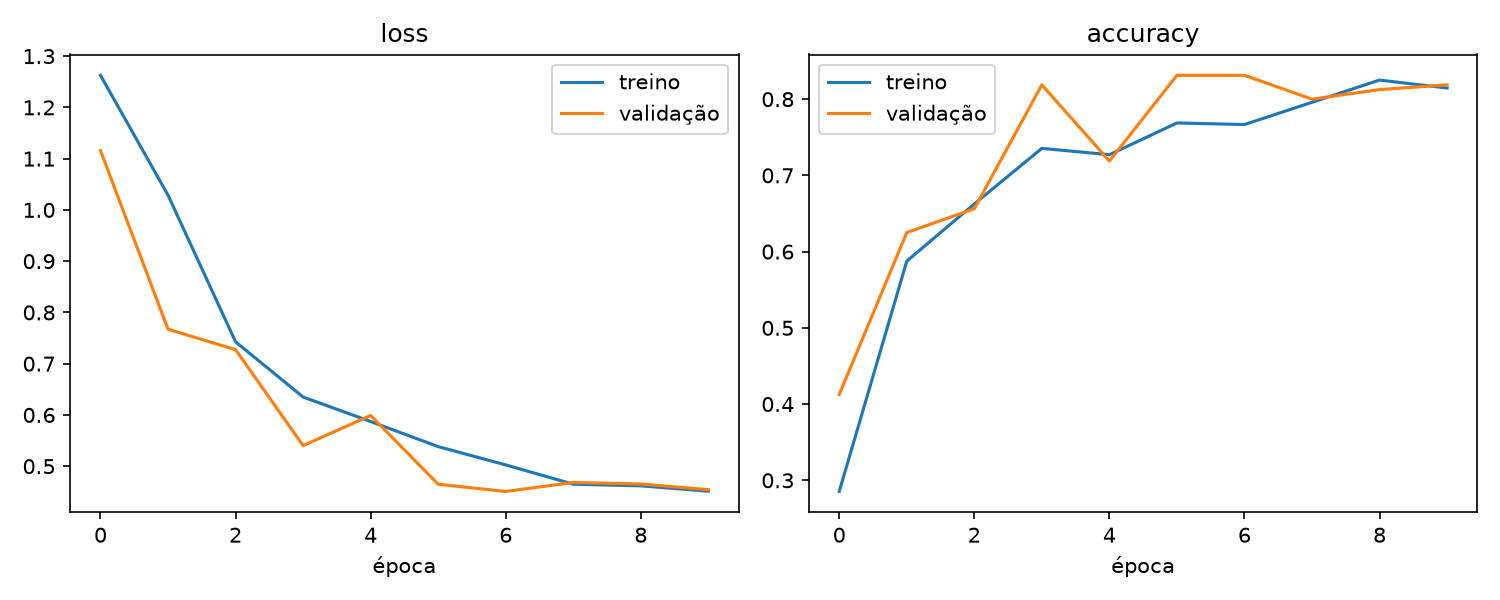

Selecionada: cnn_2
Relatório do teste: {
  "Forest": {
    "precision": 0.9487179487179487,
    "recall": 0.925,
    "f1-score": 0.9367088607594937,
    "support": 40.0
  },
  "Industrial": {
    "precision": 0.8421052631578947,
    "recall": 0.8,
    "f1-score": 0.8205128205128205,
    "support": 40.0
  },
  "Residential": {
    "precision": 0.7837837837837838,
    "recall": 0.725,
    "f1-score": 0.7532467532467533,
    "support": 40.0
  },
  "River": {
    "precision": 0.8260869565217391,
    "recall": 0.95,
    "f1-score": 0.8837209302325582,
    "support": 40.0
  },
  "accuracy": 0.85,
  "macro avg": {
    "precision": 0.8501734880453415,
    "recall": 0.8500000000000001,
    "f1-score": 0.8485473411879063,
    "support": 160.0
  },
  "weighted avg": {
    "precision": 0.8501734880453415,
    "recall": 0.85,
    "f1-score": 0.8485473411879063,
    "support": 160.0
  }
}


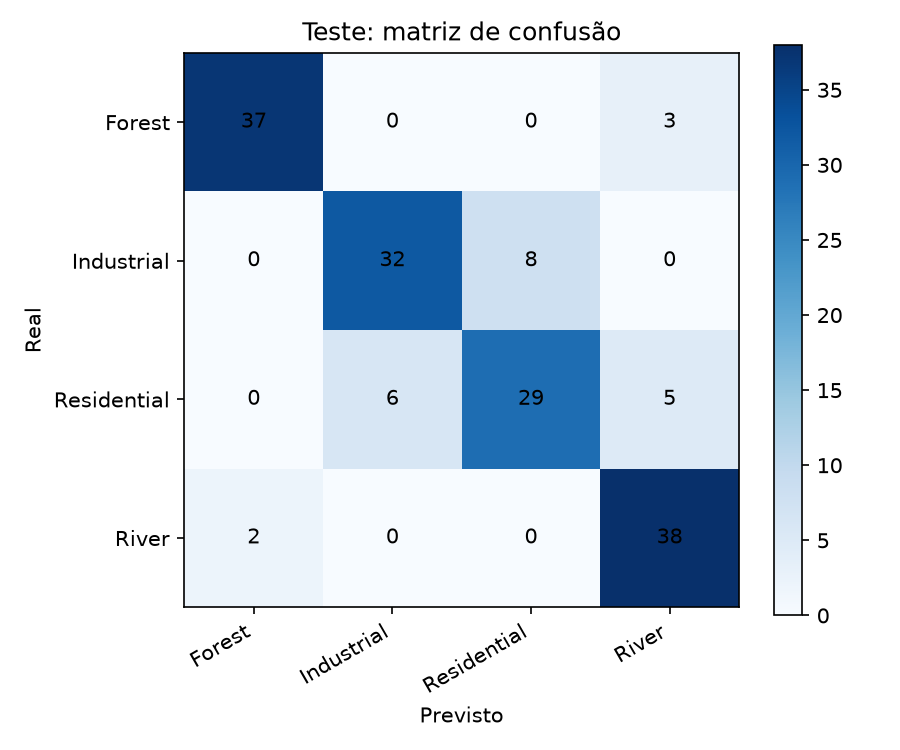

In [5]:
import json
from IPython.display import display, Image
r=json.loads((OUT/'results.json').read_text())
for e in r['experiments']:
    print(e['config']['name'], 'acurácia validação:', round(e['val_accuracy'],4), 'parâmetros:', e['parameters'])
    display(Image(filename=str(OUT/(e['config']['name']+'_curvas.png'))))
print('Selecionada:',r['best'])
print('Relatório do teste:', json.dumps(r['test_report'],ensure_ascii=False,indent=2))
display(Image(filename=str(OUT/'matriz_teste.png')))

In [6]:
linhas = []
for e in resultados["experiments"]:
    h = e["history"]
    melhor = int(np.argmin(h["val_loss"]))
    linhas.append({"modelo": e["config"]["name"], "parâmetros": e["parameters"], "épocas": e["epochs_run"],
                   "acurácia validação": e["val_accuracy"], "F1 macro validação": e["val_report"]["macro avg"]["f1-score"],
                   "menor perda validação": min(h["val_loss"]), "acurácia treino (melhor época)": h["accuracy"][melhor],
                   "gap treino − validação": h["accuracy"][melhor] - h["val_accuracy"][melhor]})
comparacao = pd.DataFrame(linhas).set_index("modelo")
comparacao.style.format({"parâmetros": "{:,.0f}", "acurácia validação": "{:.2%}", "F1 macro validação": "{:.3f}",
                         "menor perda validação": "{:.3f}", "acurácia treino (melhor época)": "{:.2%}",
                         "gap treino − validação": "{:+.2%}"}).highlight_max(subset=["acurácia validação"], color="#c8e6c9")

,parâmetros,épocas,acurácia validação,F1 macro validação,menor perda validação,acurácia treino (melhor época),gap treino − validação
modelo,,,,,,,
cnn_1,"529,700",12,85.00%,0.849,0.437,91.87%,+6.87%
cnn_2,"2,117,188",12,86.88%,0.867,0.331,90.83%,+3.96%
cnn_3,"1,142,468",10,83.12%,0.829,0.451,76.67%,-6.46%


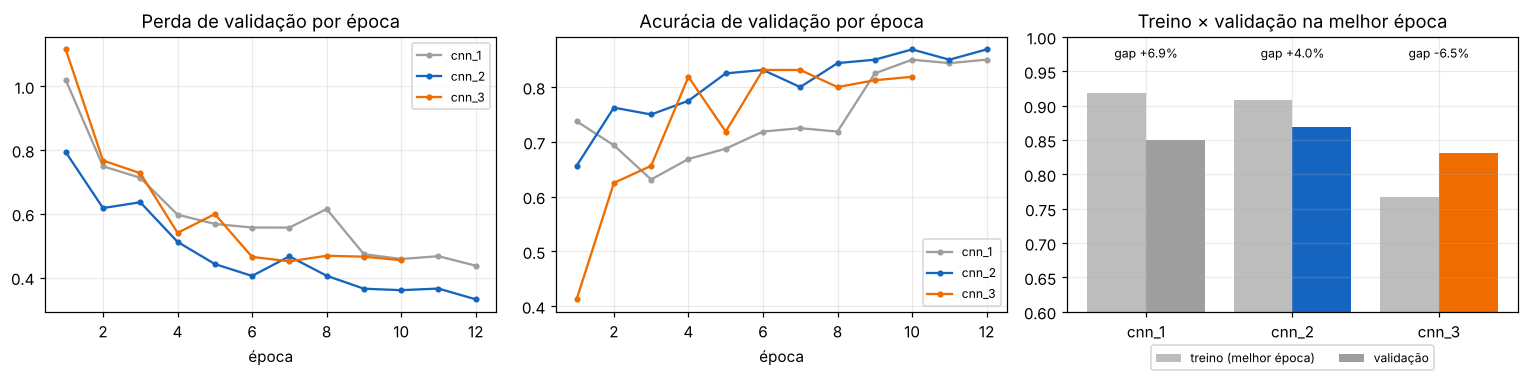

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
cores = {"cnn_1": "#9e9e9e", "cnn_2": "#1565c0", "cnn_3": "#ef6c00"}
for e in resultados["experiments"]:
    n, h = e["config"]["name"], e["history"]
    ep = range(1, len(h["loss"]) + 1)
    axs[0].plot(ep, h["val_loss"], "-o", ms=3, color=cores[n], label=n)
    axs[1].plot(ep, h["val_accuracy"], "-o", ms=3, color=cores[n], label=n)
axs[0].set(title="Perda de validação por época", xlabel="época"); axs[1].set(title="Acurácia de validação por época", xlabel="época")
x = np.arange(len(comparacao))
axs[2].bar(x - 0.2, comparacao["acurácia treino (melhor época)"], 0.4, color="#bdbdbd", label="treino (melhor época)")
axs[2].bar(x + 0.2, comparacao["acurácia validação"], 0.4, color=[cores[i] for i in comparacao.index], label="validação")
for i, g in enumerate(comparacao["gap treino − validação"]):
    axs[2].text(i, 0.97, f"gap {g:+.1%}", ha="center", fontsize=8)
axs[2].set(xticks=x, xticklabels=comparacao.index, ylim=(0.6, 1.0), title="Treino × validação na melhor época")
for a in axs[:2]: a.legend(fontsize=8)
axs[2].legend(fontsize=8, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
for a in axs: a.grid(alpha=.25)
plt.tight_layout(); plt.show()

,precisão,recall,F1,imagens
Forest,0.949,0.925,0.937,40.0
Industrial,0.842,0.800,0.821,40.0
Residential,0.784,0.725,0.753,40.0
River,0.826,0.950,0.884,40.0
média macro,0.850,0.850,0.849,160.0


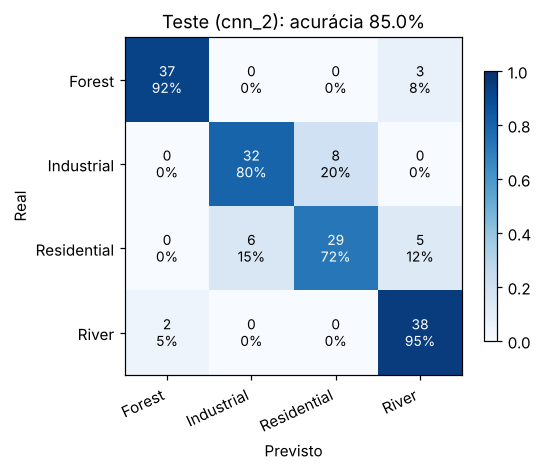

In [8]:
rel = resultados["test_report"]
por_classe = pd.DataFrame({c: rel[c] for c in CLASSES}).T[["precision", "recall", "f1-score", "support"]]
por_classe.loc["média macro"] = [rel["macro avg"][k] for k in ["precision", "recall", "f1-score", "support"]]
display(por_classe.rename(columns={"precision": "precisão", "f1-score": "F1", "support": "imagens"}).round(3))

cm = np.array(resultados["test_confusion_matrix"])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.2, 4.3))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set(xticks=range(4), yticks=range(4), xticklabels=CLASSES, yticklabels=CLASSES, xlabel="Previsto", ylabel="Real",
       title=f"Teste ({resultados['best']}): acurácia {rel['accuracy']:.1%}")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

## 5. Análise crítica

**O que cada mudança causou**

- **CNN 1 → CNN 2 (mais filtros, densa maior, dropout 0,25):** a acurácia de validação subiu de 85,0 % para 86,9 % e a menor perda de validação caiu de 0,437 para 0,331 — a maior melhora entre os experimentos. Mais filtros permitem distinguir texturas parecidas, e o dropout segurou o crescimento do gap de treino.
- **CNN 2 → CNN 3 (terceiro bloco, dropout 0,35, taxa 0,0005):** a validação caiu para 83,1 % e a acurácia de **treino** ficou abaixo da de validação (76,7 % na melhor época; 81,5 % na última). É um quadro de **subajuste** dentro do limite de 12 épocas: regularização mais forte somada a um passo de aprendizado menor fez a rede aprender mais devagar. Mais profundidade não ajudou com só 480 imagens de treino.
- Como cada experimento mudou mais de um hiperparâmetro, a comparação mostra o efeito do conjunto de mudanças, não de cada uma isoladamente.

**Sobreajuste e subajuste.** Na CNN 2, a acurácia de treino na melhor época ficou poucos pontos acima da validação (gap moderado), e a perda de validação ainda caía na 12ª época — um sinal de que **mais épocas** poderiam melhorar o resultado. A CNN 1, sem dropout, chegou a 92 % no treino com perda de validação maior, o padrão típico de começo de sobreajuste.

**Avaliação final (teste, 160 imagens).** A CNN 2 teve **85,0 % de acurácia** e F1 macro de 0,849, próximo da validação (86,9 %), o que indica que a escolha não foi sorte da partição de validação. Forest (F1 0,94) e River (0,88) são as classes mais fáceis; **Industrial × Residential** concentram os erros (8 industriais previstas como residenciais e 6 no sentido oposto), porque ambas têm telhados, ruas e cores semelhantes em 64 × 64 pixels. Cinco imagens residenciais foram previstas como River, possivelmente por vegetação ou corpos d'água no recorte.

**Por que a CNN 2:** melhor acurácia e melhor perda de validação, gap moderado e desempenho estável no teste. O custo é ter mais parâmetros (2,1 M), irrelevante para um app de uma imagem por vez.

## 6. Aplicação web (Gradio)

A célula abaixo carrega `outputs/best.keras`, recebe uma imagem pelo navegador, aplica **o mesmo pré-processamento do treino** (RGB, 64 × 64, pixels/255) e mostra a imagem enviada, a classe prevista e a probabilidade de cada uma das quatro classes.

- **No Google Colab:** execute a célula; o Gradio cria um link público temporário (`*.gradio.live`) que abre em qualquer navegador.
- **Localmente:** `python src/app.py` e acesse `http://127.0.0.1:7860`.
- A célula fica **sem saída salva** porque inicia um servidor; para usar o app, basta executá-la depois do treinamento (ou com `outputs/best.keras` já gerado).

In [ ]:
"""Aplicação Gradio para modelo final, sem alegar previsão hídrica."""
import os
import sys
from pathlib import Path
import numpy as np
import tensorflow as tf
import gradio as gr

ROOT=Path(os.environ.get('CNN_ROOT', Path.cwd())).resolve()
MODEL=ROOT/'outputs'/'best.keras'
if not MODEL.exists(): raise SystemExit('Execute src/train.py antes de iniciar a aplicação: outputs/best.keras não existe.')
model=tf.keras.models.load_model(MODEL)
classes=['Forest','Industrial','Residential','River']
def classify(image):
    if image is None: raise gr.Error('Selecione uma imagem antes de classificar.')
    image=image.convert('RGB').resize((64,64))
    x=np.asarray(image,dtype='float32')[None,...]/255.0
    probabilities=model.predict(x,verbose=0)[0]
    return {label:float(probabilities[i]) for i,label in enumerate(classes)}
with gr.Blocks(title='Territory Vision') as app:
    gr.Markdown('# Territory Vision\nClassificação experimental de imagens semelhantes às do EuroSAT. O resultado não mede escassez hídrica nem substitui análise especializada.')
    inp=gr.Image(type='pil',label='Imagem de satélite')
    out=gr.Label(num_top_classes=4,label='Classe prevista e probabilidades')
    gr.Button('Classificar').click(classify,inp,out)
# No Google Colab, share=True gera um link público temporário (*.gradio.live).
app.launch(share='google.colab' in sys.modules)


## 7. Uso de IA generativa

Usamos IA generativa como ferramenta de apoio: para tirar dúvidas sobre camadas e hiperparâmetros, sugerir trechos de código, ajudar na depuração e revisar textos. As sugestões foram avaliadas pelos resultados executados — por exemplo, a CNN 3 (mais profunda e mais regularizada) foi testada e descartada porque piorou a validação. Todos os números foram conferidos em `outputs/results.json`, e a dupla consegue explicar a arquitetura, o treinamento e as decisões do projeto.

## 8. Conclusões, limitações e melhorias

**Conclusões.** Uma CNN própria com dois blocos convolucionais (32 e 64 filtros), densa de 128 e dropout 0,25 classificou as quatro classes com 85 % de acurácia no teste. Mais filtros ajudaram; mais profundidade com regularização forte e passo menor prejudicou dentro de 12 épocas. A aplicação web permite que qualquer pessoa use o modelo pelo navegador.

**Limitações.** Amostra pequena (800 imagens) e uma única semente; a divisão aleatória pode colocar imagens de áreas vizinhas em conjuntos diferentes; as pontuações softmax não são probabilidades calibradas; imagens de outros sensores, resoluções ou estações podem ser classificadas incorretamente. A classe River indica a presença visual de um rio, não a disponibilidade de água.

**Próximos passos.** (1) Treinar por mais épocas a CNN 2, já que a perda de validação ainda caía; (2) testar BatchNormalization e *data augmentation* (rotações e espelhamentos, válidos em imagens de satélite); (3) isolar uma mudança por experimento para medir o efeito de cada hiperparâmetro; (4) usar mais imagens do EuroSAT e validação cruzada com várias sementes; (5) calibrar as probabilidades exibidas no app.